EV Charging Station Distance Matrix


,START,CS1,CS2,CS3,CS4,CS5,CS6,CS7,CS8,DEST
START,0.00,52.61,35.61,35.36,72.80,57.97,80.80,72.03,71.59,88.02
CS1,52.61,0.00,27.78,63.07,36.50,60.61,57.14,83.74,19.31,76.66
CS2,35.61,27.78,0.00,35.47,37.20,36.40,47.42,58.31,42.58,60.13
CS3,35.36,63.07,35.47,0.00,63.64,29.00,60.90,37.12,77.62,59.82
CS4,72.80,36.50,37.20,63.64,0.00,44.64,23.26,66.21,31.38,46.04
CS5,57.97,60.61,36.40,29.00,44.64,0.00,34.21,23.35,68.60,31.06
CS6,80.80,57.14,47.42,60.90,23.26,34.21,0.00,50.49,54.63,23.35
CS7,72.03,83.74,58.31,37.12,66.21,23.35,50.49,0.00,91.83,35.44
CS8,71.59,19.31,42.58,77.62,31.38,68.60,54.63,91.83,0.00,77.03
DEST,88.02,76.66,60.13,59.82,46.04,31.06,23.35,35.44,77.03,0.00


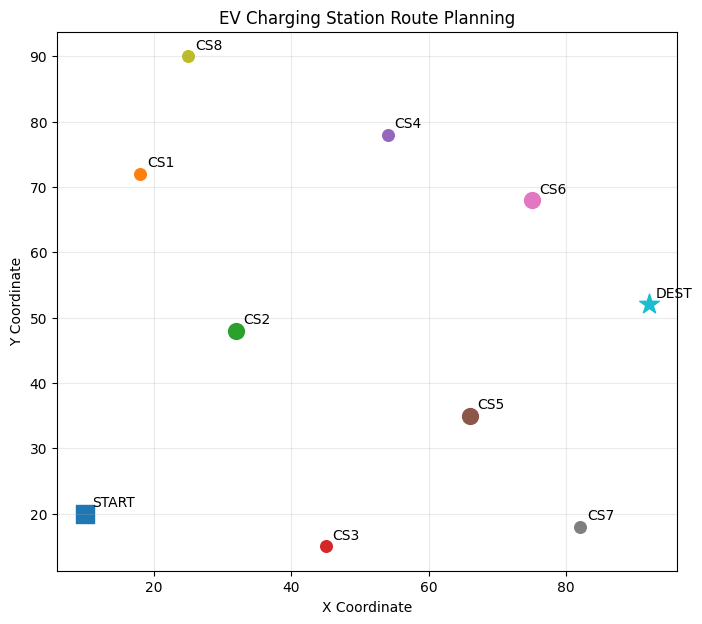


Required Charging Stations:
{'CS6', 'CS5', 'CS2'}

Battery Capacity: 60.0 kWh
Initial Battery: 45.0 kWh
Minimum Battery: 5.0 kWh
Energy Consumption: 0.18 kWh/km
Charging Amount: 30.0 kWh


In [ ]:
ccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccccc# =========================================================
# CELL 0 — IMPORTS + EV PROBLEM SETUP
# =========================================================

import heapq
import math
import random
import time
import tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------------------------------------------------
# NODE NAMES
# ---------------------------------------------------------

NODE_NAMES = [
    "START",
    "CS1", "CS2", "CS3", "CS4",
    "CS5", "CS6", "CS7", "CS8",
    "DEST"
]

# ---------------------------------------------------------
# COORDINATES
# ---------------------------------------------------------

COORDS = {
    "START": (10, 20),

    "CS1": (18, 72),
    "CS2": (32, 48),
    "CS3": (45, 15),
    "CS4": (54, 78),
    "CS5": (66, 35),
    "CS6": (75, 68),
    "CS7": (82, 18),
    "CS8": (25, 90),

    "DEST": (92, 52)
}

# ---------------------------------------------------------
# EV PARAMETERS
# ---------------------------------------------------------

BATTERY_CAPACITY = 60.0
INITIAL_BATTERY = 45.0
MIN_BATTERY = 5.0

# Energy consumed per kilometre
ENERGY_PER_KM = 0.18

# Energy added at a charging station
CHARGE_AMOUNT = 30.0

# Required charging stations
REQUIRED_STATIONS = {
    "CS2",
    "CS5",
    "CS6"
}


# ---------------------------------------------------------
# DISTANCE MATRIX
# ---------------------------------------------------------

def build_distance_matrix(nodes):

    n = len(nodes)

    d = np.zeros(
        (n, n),
        dtype=float
    )

    for i in range(n):

        for j in range(n):

            if i != j:

                x1, y1 = COORDS[nodes[i]]
                x2, y2 = COORDS[nodes[j]]

                d[i, j] = round(
                    math.hypot(
                        x1 - x2,
                        y1 - y2
                    ),
                    2
                )

    return d


DIST = build_distance_matrix(
    NODE_NAMES
)


# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------

def node_index(node):

    return NODE_NAMES.index(node)


def route_distance(
    route,
    dist=DIST
):

    if not route:
        return float("inf")

    return sum(
        dist[
            route[i],
            route[i + 1]
        ]
        for i in range(
            len(route) - 1
        )
    )


def route_text(route):

    if route is None:
        return "No feasible route"

    return " -> ".join(
        NODE_NAMES[i]
        for i in route
    )


def energy_required(
    a,
    b
):

    return (
        DIST[
            node_index(a),
            node_index(b)
        ]
        * ENERGY_PER_KM
    )


def charge_battery(
    station,
    battery
):

    if station in REQUIRED_STATIONS:

        return min(
            BATTERY_CAPACITY,
            battery + CHARGE_AMOUNT
        )

    return battery


# ---------------------------------------------------------
# DISPLAY PROBLEM
# ---------------------------------------------------------

distance_df = pd.DataFrame(
    DIST,
    index=NODE_NAMES,
    columns=NODE_NAMES
)

print(
    "EV Charging Station Distance Matrix"
)

display(
    distance_df
)


plt.figure(
    figsize=(8, 7)
)

for node in NODE_NAMES:

    x, y = COORDS[node]

    if node == "START":

        plt.scatter(
            x,
            y,
            s=180,
            marker="s"
        )

    elif node == "DEST":

        plt.scatter(
            x,
            y,
            s=220,
            marker="*"
        )

    elif node in REQUIRED_STATIONS:

        plt.scatter(
            x,
            y,
            s=130,
            marker="o"
        )

    else:

        plt.scatter(
            x,
            y,
            s=70
        )

    plt.annotate(
        node,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )


plt.title(
    "EV Charging Station Route Planning"
)

plt.xlabel(
    "X Coordinate"
)

plt.ylabel(
    "Y Coordinate"
)

plt.grid(
    alpha=0.25
)

plt.show()


print("\nRequired Charging Stations:")
print(REQUIRED_STATIONS)

print("\nBattery Capacity:", BATTERY_CAPACITY, "kWh")
print("Initial Battery:", INITIAL_BATTERY, "kWh")
print("Minimum Battery:", MIN_BATTERY, "kWh")
print("Energy Consumption:", ENERGY_PER_KM, "kWh/km")
print("Charging Amount:", CHARGE_AMOUNT, "kWh")

In [ ]:
# =========================================================
# CELL 1 — UNINFORMED SEARCH
# BFS, DFS, UCS
# =========================================================


def make_state(
    node,
    visited,
    battery
):

    return (
        node,
        frozenset(visited),
        round(battery, 1)
    )


def goal_reached(
    node,
    visited
):

    destination = node_index("DEST")

    return (
        node == destination
        and
        REQUIRED_STATIONS.issubset(
            visited
        )
    )


def get_neighbors(
    current,
    visited
):

    neighbors = []

    for nxt in range(
        len(NODE_NAMES)
    ):

        if nxt == current:
            continue

        station = NODE_NAMES[nxt]

        # Do not visit START again
        if station == "START":
            continue

        # DESTINATION can only be visited
        # after all required charging stations
        # have been completed.

        if (
            station == "DEST"
            and
            not REQUIRED_STATIONS.issubset(
                visited
            )
        ):

            continue

        neighbors.append(nxt)

    return neighbors


# =========================================================
# COMMON TRANSITION FUNCTION
# =========================================================

def transition(
    current,
    nxt,
    visited,
    battery,
    dist
):

    distance = dist[
        current,
        nxt
    ]

    energy = (
        distance *
        ENERGY_PER_KM
    )

    new_battery = (
        battery - energy
    )

    # Battery constraint
    if new_battery < MIN_BATTERY:

        return None

    new_visited = set(
        visited
    )

    station = NODE_NAMES[nxt]

    # Charge when required station is reached
    if station in REQUIRED_STATIONS:

        new_visited.add(
            station
        )

        new_battery = min(
            BATTERY_CAPACITY,
            new_battery + CHARGE_AMOUNT
        )

    return (
        new_battery,
        frozenset(new_visited),
        distance
    )


# =========================================================
# BFS
# =========================================================

def bfs_ev(
    dist,
    start=0
):

    initial_state = (
        start,
        frozenset(),
        INITIAL_BATTERY
    )

    queue = deque([
        (
            initial_state,
            [start],
            0.0
        )
    ])

    visited_states = set()

    expanded = 0

    while queue:

        state, path, cost = queue.popleft()

        current, visited, battery = state

        state_key = make_state(
            current,
            visited,
            battery
        )

        if state_key in visited_states:
            continue

        visited_states.add(
            state_key
        )

        expanded += 1

        if goal_reached(
            current,
            visited
        ):

            return (
                path,
                cost,
                expanded
            )

        for nxt in get_neighbors(
            current,
            visited
        ):

            result = transition(
                current,
                nxt,
                visited,
                battery,
                dist
            )

            if result is None:
                continue

            new_battery, new_visited, distance = result

            new_state = (
                nxt,
                new_visited,
                new_battery
            )

            queue.append(
                (
                    new_state,
                    path + [nxt],
                    cost + distance
                )
            )

    return (
        None,
        float("inf"),
        expanded
    )


# =========================================================
# DFS
# =========================================================

def dfs_ev(
    dist,
    start=0
):

    initial_state = (
        start,
        frozenset(),
        INITIAL_BATTERY
    )

    stack = [
        (
            initial_state,
            [start],
            0.0
        )
    ]

    visited_states = set()

    expanded = 0

    while stack:

        state, path, cost = stack.pop()

        current, visited, battery = state

        state_key = make_state(
            current,
            visited,
            battery
        )

        if state_key in visited_states:
            continue

        visited_states.add(
            state_key
        )

        expanded += 1

        if goal_reached(
            current,
            visited
        ):

            return (
                path,
                cost,
                expanded
            )

        neighbors = get_neighbors(
            current,
            visited
        )

        for nxt in reversed(
            neighbors
        ):

            result = transition(
                current,
                nxt,
                visited,
                battery,
                dist
            )

            if result is None:
                continue

            new_battery, new_visited, distance = result

            new_state = (
                nxt,
                new_visited,
                new_battery
            )

            stack.append(
                (
                    new_state,
                    path + [nxt],
                    cost + distance
                )
            )

    return (
        None,
        float("inf"),
        expanded
    )


# =========================================================
# UNIFORM COST SEARCH
# =========================================================

def ucs_ev(
    dist,
    start=0
):

    initial_state = (
        start,
        frozenset(),
        INITIAL_BATTERY
    )

    priority_queue = []

    counter = 0

    heapq.heappush(
        priority_queue,
        (
            0.0,
            counter,
            initial_state,
            [start]
        )
    )

    best_cost = {}

    expanded = 0

    while priority_queue:

        cost, _, state, path = (
            heapq.heappop(
                priority_queue
            )
        )

        current, visited, battery = state

        state_key = make_state(
            current,
            visited,
            battery
        )

        if (
            state_key in best_cost
            and
            best_cost[state_key] <= cost
        ):
            continue

        best_cost[state_key] = cost

        expanded += 1

        if goal_reached(
            current,
            visited
        ):

            return (
                path,
                cost,
                expanded
            )

        for nxt in get_neighbors(
            current,
            visited
        ):

            result = transition(
                current,
                nxt,
                visited,
                battery,
                dist
            )

            if result is None:
                continue

            new_battery, new_visited, distance = result

            new_state = (
                nxt,
                new_visited,
                new_battery
            )

            counter += 1

            heapq.heappush(
                priority_queue,
                (
                    cost + distance,
                    counter,
                    new_state,
                    path + [nxt]
                )
            )

    return (
        None,
        float("inf"),
        expanded
    )


print("BFS, DFS and UCS functions loaded successfully.")

BFS, DFS and UCS functions loaded successfully.


In [ ]:
# =========================================================
# CELL 2 — INFORMED SEARCH
# Greedy Best-First + A*
# =========================================================


def heuristic(
    current,
    visited
):

    destination = node_index(
        "DEST"
    )

    remaining = [
        node_index(station)
        for station in REQUIRED_STATIONS
        if station not in visited
    ]

    # All required stations completed
    if not remaining:

        return DIST[
            current,
            destination
        ]

    nearest_station = min(
        DIST[
            current,
            station
        ]
        for station in remaining
    )

    nearest_destination = min(
        DIST[
            station,
            destination
        ]
        for station in remaining
    )

    return (
        nearest_station
        +
        nearest_destination
    )


# =========================================================
# GREEDY BEST-FIRST SEARCH
# =========================================================

def greedy_ev(
    dist,
    start=0
):

    initial_state = (
        start,
        frozenset(),
        INITIAL_BATTERY
    )

    pq = []

    counter = 0

    heapq.heappush(
        pq,
        (
            heuristic(
                start,
                set()
            ),
            counter,
            initial_state,
            [start],
            0.0
        )
    )

    visited_states = set()

    expanded = 0

    while pq:

        _, _, state, path, cost = (
            heapq.heappop(pq)
        )

        current, visited, battery = state

        state_key = make_state(
            current,
            visited,
            battery
        )

        if state_key in visited_states:
            continue

        visited_states.add(
            state_key
        )

        expanded += 1

        if goal_reached(
            current,
            visited
        ):

            return (
                path,
                cost,
                expanded
            )

        for nxt in get_neighbors(
            current,
            visited
        ):

            result = transition(
                current,
                nxt,
                visited,
                battery,
                dist
            )

            if result is None:
                continue

            new_battery, new_visited, distance = result

            new_state = (
                nxt,
                new_visited,
                new_battery
            )

            counter += 1

            heapq.heappush(
                pq,
                (
                    heuristic(
                        nxt,
                        new_visited
                    ),
                    counter,
                    new_state,
                    path + [nxt],
                    cost + distance
                )
            )

    return (
        None,
        float("inf"),
        expanded
    )


# =========================================================
# A*
# =========================================================

def astar_ev(
    dist,
    start=0
):

    initial_state = (
        start,
        frozenset(),
        INITIAL_BATTERY
    )

    pq = []

    counter = 0

    heapq.heappush(
        pq,
        (
            heuristic(
                start,
                set()
            ),
            0.0,
            counter,
            initial_state,
            [start]
        )
    )

    best_g = {}

    expanded = 0

    while pq:

        f, g, _, state, path = (
            heapq.heappop(pq)
        )

        current, visited, battery = state

        state_key = make_state(
            current,
            visited,
            battery
        )

        if (
            state_key in best_g
            and
            best_g[state_key] <= g
        ):
            continue

        best_g[state_key] = g

        expanded += 1

        if goal_reached(
            current,
            visited
        ):

            return (
                path,
                g,
                expanded
            )

        for nxt in get_neighbors(
            current,
            visited
        ):

            result = transition(
                current,
                nxt,
                visited,
                battery,
                dist
            )

            if result is None:
                continue

            new_battery, new_visited, distance = result

            new_g = g + distance

            new_h = heuristic(
                nxt,
                new_visited
            )

            new_state = (
                nxt,
                new_visited,
                new_battery
            )

            counter += 1

            heapq.heappush(
                pq,
                (
                    new_g + new_h,
                    new_g,
                    counter,
                    new_state,
                    path + [nxt]
                )
            )

    return (
        None,
        float("inf"),
        expanded
    )


print(
    "Greedy Best-First and A* functions loaded successfully."
)

Greedy Best-First and A* functions loaded successfully.


In [ ]:
# =========================================================
# CHECK WHETHER ROUTE IS FEASIBLE
# =========================================================

def route_is_feasible(route):

    battery = INITIAL_BATTERY

    visited_required = set()

    for i in range(len(route) - 1):

        current = route[i]
        nxt = route[i + 1]

        distance = DIST[
            current,
            nxt
        ]

        energy = (
            distance *
            ENERGY_PER_KM
        )

        battery -= energy

        if battery < MIN_BATTERY:

            return False

        station_name = NODE_NAMES[nxt]

        if station_name in REQUIRED_STATIONS:

            visited_required.add(
                station_name
            )

            battery = charge_battery(
                station_name,
                battery
            )

    return (
        route[-1] == node_index("DEST")
        and
        REQUIRED_STATIONS.issubset(
            visited_required
        )
    )


# =========================================================
# HILL CLIMBING
# =========================================================

def hill_climbing_ev(
    dist,
    restarts=30,
    max_iter=1000
):

    start = node_index("START")
    destination = node_index("DEST")

    required_indices = [
        node_index(x)
        for x in REQUIRED_STATIONS
    ]

    best_global_route = None
    best_global_cost = float("inf")

    total_iterations = 0
    successful_restarts = 0

    for _ in range(restarts):

        middle = required_indices.copy()

        random.shuffle(middle)

        current = [
            start
        ] + middle + [
            destination
        ]

        # If initial ordering is infeasible,
        # try random permutations until feasible.
        attempts = 0

        while (
            not route_is_feasible(current)
            and attempts < 50
        ):

            random.shuffle(middle)

            current = [
                start
            ] + middle + [
                destination
            ]

            attempts += 1

        if not route_is_feasible(current):

            continue

        current_cost = route_distance(
            current,
            dist
        )

        improved = False

        for _ in range(max_iter):

            total_iterations += 1

            best_neighbor = current
            best_neighbor_cost = current_cost

            for i in range(
                1,
                len(current) - 2
            ):

                for j in range(
                    i + 1,
                    len(current) - 1
                ):

                    neighbor = current.copy()

                    neighbor[i], neighbor[j] = (
                        neighbor[j],
                        neighbor[i]
                    )

                    if not route_is_feasible(
                        neighbor
                    ):
                        continue

                    cost = route_distance(
                        neighbor,
                        dist
                    )

                    if cost < best_neighbor_cost:

                        best_neighbor = neighbor
                        best_neighbor_cost = cost

            if (
                best_neighbor_cost
                >= current_cost
            ):

                break

            current = best_neighbor
            current_cost = best_neighbor_cost

            improved = True

        if improved:

            successful_restarts += 1

        if current_cost < best_global_cost:

            best_global_route = current.copy()
            best_global_cost = current_cost

    return (
        best_global_route,
        best_global_cost,
        total_iterations,
        successful_restarts
    )


# =========================================================
# GENETIC ALGORITHM
# =========================================================

def genetic_algorithm_ev(
    dist,
    population_size=80,
    generations=300,
    mutation_rate=0.08,
    elite_size=4
):

    start = node_index("START")
    destination = node_index("DEST")

    required = [
        node_index(x)
        for x in REQUIRED_STATIONS
    ]

    def make_route():

        middle = required.copy()

        random.shuffle(middle)

        return [
            start
        ] + middle + [
            destination
        ]

    def fitness(route):

        if not route_is_feasible(route):

            return 1e-12

        return 1.0 / (
            route_distance(route, dist)
            + 1e-12
        )

    def mutate(route):

        if random.random() < mutation_rate:

            i, j = random.sample(
                range(
                    1,
                    len(route) - 1
                ),
                2
            )

            route[i], route[j] = (
                route[j],
                route[i]
            )

    def crossover(parent1, parent2):

        n = len(parent1)

        child = [
            None
        ] * n

        child[0] = start
        child[-1] = destination

        a, b = sorted(
            random.sample(
                range(1, n - 1),
                2
            )
        )

        child[a:b] = parent1[a:b]

        used = set(
            x for x in child
            if x is not None
        )

        remaining = [
            x for x in parent2
            if x not in used
            and x != start
            and x != destination
        ]

        k = 0

        for i in range(
            1,
            n - 1
        ):

            if child[i] is None:

                child[i] = remaining[k]

                k += 1

        return child

    population = [
        make_route()
        for _ in range(population_size)
    ]

    best_route = min(
        population,
        key=lambda r: (
            route_distance(r, dist)
            if route_is_feasible(r)
            else float("inf")
        )
    )

    best_cost = (
        route_distance(best_route, dist)
        if route_is_feasible(best_route)
        else float("inf")
    )

    history = []

    for _ in range(generations):

        fitness_values = [
            fitness(r)
            for r in population
        ]

        elite_indices = np.argsort(
            fitness_values
        )[-elite_size:][::-1]

        elites = [
            population[i].copy()
            for i in elite_indices
        ]

        weights = np.array(
            fitness_values
        )

        if weights.sum() == 0:

            weights = np.ones(
                len(weights)
            )

        weights = (
            weights /
            weights.sum()
        )

        selected_indices = np.random.choice(
            len(population),
            size=population_size - elite_size,
            p=weights
        )

        selected = elites + [
            population[i].copy()
            for i in selected_indices
        ]

        new_population = elites.copy()

        while len(new_population) < population_size:

            p1, p2 = random.sample(
                selected,
                2
            )

            child = crossover(
                p1,
                p2
            )

            mutate(child)

            new_population.append(
                child
            )

        population = new_population

        feasible_routes = [
            r for r in population
            if route_is_feasible(r)
        ]

        if feasible_routes:

            current_best = min(
                feasible_routes,
                key=lambda r:
                route_distance(r, dist)
            )

            current_cost = route_distance(
                current_best,
                dist
            )

            if current_cost < best_cost:

                best_route = current_best.copy()
                best_cost = current_cost

        history.append(
            best_cost
        )

    return (
        best_route,
        best_cost,
        generations,
        history
    )

In [ ]:
# =========================================================
# CSP BACKTRACKING
# =========================================================

def backtracking_csp_ev(dist):

    start = node_index("START")
    destination = node_index("DEST")

    required = set(
        node_index(x)
        for x in REQUIRED_STATIONS
    )

    best_route = None
    best_cost = float("inf")

    expanded = 0

    def search(
        current,
        path,
        visited,
        battery,
        cost
    ):

        nonlocal best_route
        nonlocal best_cost
        nonlocal expanded

        expanded += 1

        # Goal
        if (
            visited == required
            and current == destination
        ):

            if cost < best_cost:

                best_cost = cost
                best_route = path.copy()

            return

        # If all required stations visited,
        # try destination
        if visited == required:

            nxt = destination

            distance = dist[
                current,
                nxt
            ]

            energy = (
                distance *
                ENERGY_PER_KM
            )

            if (
                battery - energy
                >= MIN_BATTERY
            ):

                search(
                    nxt,
                    path + [nxt],
                    visited,
                    battery - energy,
                    cost + distance
                )

            return

        remaining = (
            required - visited
        )

        candidates = sorted(
            remaining,
            key=lambda x:
            dist[current, x]
        )

        for nxt in candidates:

            distance = dist[
                current,
                nxt
            ]

            energy = (
                distance *
                ENERGY_PER_KM
            )

            new_battery = (
                battery - energy
            )

            if new_battery < MIN_BATTERY:

                continue

            new_visited = visited.copy()

            new_visited.add(
                nxt
            )

            new_battery = min(
                BATTERY_CAPACITY,
                new_battery + CHARGE_AMOUNT
            )

            new_cost = (
                cost + distance
            )

            if new_cost >= best_cost:

                continue

            search(
                nxt,
                path + [nxt],
                new_visited,
                new_battery,
                new_cost
            )

    search(
        start,
        [start],
        set(),
        INITIAL_BATTERY,
        0.0
    )

    return (
        best_route,
        best_cost,
        expanded
    )


# =========================================================
# BRANCH AND BOUND
# =========================================================

def branch_and_bound_ev(dist):

    start = node_index("START")
    destination = node_index("DEST")

    required = set(
        node_index(x)
        for x in REQUIRED_STATIONS
    )

    best_route = None
    best_cost = float("inf")

    expanded = 0

    def lower_bound(
        current,
        remaining
    ):

        if not remaining:

            return dist[
                current,
                destination
            ]

        nearest_required = min(
            dist[current, x]
            for x in remaining
        )

        nearest_destination = min(
            dist[x, destination]
            for x in remaining
        )

        return (
            nearest_required
            + nearest_destination
        )

    def search(
        current,
        path,
        visited,
        battery,
        cost
    ):

        nonlocal best_route
        nonlocal best_cost
        nonlocal expanded

        expanded += 1

        remaining = (
            required - visited
        )

        # Goal
        if not remaining:

            distance = dist[
                current,
                destination
            ]

            energy = (
                distance *
                ENERGY_PER_KM
            )

            if (
                battery - energy
                >= MIN_BATTERY
            ):

                total = (
                    cost + distance
                )

                if total < best_cost:

                    best_cost = total

                    best_route = (
                        path + [
                            destination
                        ]
                    )

            return

        # Branch and Bound pruning
        bound = (
            cost +
            lower_bound(
                current,
                remaining
            )
        )

        if bound >= best_cost:

            return

        candidates = sorted(
            remaining,
            key=lambda x:
            dist[current, x]
        )

        for nxt in candidates:

            distance = dist[
                current,
                nxt
            ]

            energy = (
                distance *
                ENERGY_PER_KM
            )

            new_battery = (
                battery - energy
            )

            if new_battery < MIN_BATTERY:

                continue

            new_visited = visited.copy()

            new_visited.add(
                nxt
            )

            new_battery = min(
                BATTERY_CAPACITY,
                new_battery + CHARGE_AMOUNT
            )

            new_cost = (
                cost + distance
            )

            if new_cost >= best_cost:

                continue

            search(
                nxt,
                path + [nxt],
                new_visited,
                new_battery,
                new_cost
            )

    search(
        start,
        [start],
        set(),
        INITIAL_BATTERY,
        0.0
    )

    return (
        best_route,
        best_cost,
        expanded
    )

In [ ]:
# =========================================================
# CELL 5 — RUN ALL SEARCH ALGORITHMS
# =========================================================

# ---------------------------------------------------------
# CHECK THAT REQUIRED FUNCTIONS EXIST
# ---------------------------------------------------------

required_functions = [
    "bfs_ev",
    "dfs_ev",
    "ucs_ev",
    "greedy_ev",
    "astar_ev",
    "hill_climbing_ev",
    "genetic_algorithm_ev",
    "backtracking_csp_ev",
    "branch_and_bound_ev"
]

missing_functions = [
    name
    for name in required_functions
    if name not in globals()
]

if missing_functions:

    raise RuntimeError(
        "These functions are missing: "
        + ", ".join(missing_functions)
        + "\n\n"
        "Run Cells 0 → 4 first."
    )


# ---------------------------------------------------------
# PERFORMANCE MEASUREMENT
# ---------------------------------------------------------

def run_one(
    name,
    fn
):

    tracemalloc.start()

    start_time = time.perf_counter()

    output = fn()

    elapsed = (
        time.perf_counter()
        - start_time
    )

    current, peak = (
        tracemalloc
        .get_traced_memory()
    )

    tracemalloc.stop()

    memory_mb = (
        peak /
        (1024 ** 2)
    )

    return (
        output,
        elapsed,
        memory_mb
    )


# ---------------------------------------------------------
# RESULT STORAGE
# ---------------------------------------------------------

results = []


def add_result(
    name,
    route,
    cost,
    elapsed,
    memory_mb,
    expanded=None,
    iterations=None,
    generations=None,
    success=None
):

    results.append({

        "Algorithm":
            name,

        "Route":
            route_text(route),

        "Distance (km)":
            round(
                cost,
                2
            )
            if np.isfinite(cost)
            else np.nan,

        "Time (s)":
            round(
                elapsed,
                6
            ),

        "Peak Memory (MB)":
            round(
                memory_mb,
                3
            ),

        "States Expanded":
            expanded,

        "Iterations":
            iterations,

        "Generations":
            generations,

        "Success / Restarts":
            success
    })


# =========================================================
# 1. BFS
# =========================================================

output, elapsed, memory = run_one(
    "BFS",
    lambda: bfs_ev(DIST)
)

route, cost, expanded = output

add_result(
    "BFS",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 2. DFS
# =========================================================

output, elapsed, memory = run_one(
    "DFS",
    lambda: dfs_ev(DIST)
)

route, cost, expanded = output

add_result(
    "DFS",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 3. UCS
# =========================================================

output, elapsed, memory = run_one(
    "Uniform Cost Search",
    lambda: ucs_ev(DIST)
)

route, cost, expanded = output

add_result(
    "Uniform Cost Search",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 4. GREEDY
# =========================================================

output, elapsed, memory = run_one(
    "Greedy Best-First",
    lambda: greedy_ev(DIST)
)

route, cost, expanded = output

add_result(
    "Greedy Best-First",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 5. A*
# =========================================================

output, elapsed, memory = run_one(
    "A*",
    lambda: astar_ev(DIST)
)

route, cost, expanded = output

add_result(
    "A*",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 6. HILL CLIMBING
# =========================================================

output, elapsed, memory = run_one(
    "Hill Climbing",
    lambda: hill_climbing_ev(
        DIST,
        restarts=20,
        max_iter=500
    )
)

route, cost, iterations, success = output

add_result(
    "Hill Climbing",
    route,
    cost,
    elapsed,
    memory,
    iterations=iterations,
    success=success
)


# =========================================================
# 7. GENETIC ALGORITHM
# =========================================================

output, elapsed, memory = run_one(
    "Genetic Algorithm",
    lambda: genetic_algorithm_ev(
        DIST,
        population_size=60,
        generations=150,
        mutation_rate=0.08
    )
)

route, cost, generations, history = output

add_result(
    "Genetic Algorithm",
    route,
    cost,
    elapsed,
    memory,
    generations=generations
)


# =========================================================
# 8. CSP BACKTRACKING
# =========================================================

output, elapsed, memory = run_one(
    "CSP Backtracking",
    lambda: backtracking_csp_ev(DIST)
)

route, cost, expanded = output

add_result(
    "CSP Backtracking",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# 9. CSP BRANCH & BOUND
# =========================================================

output, elapsed, memory = run_one(
    "CSP Branch & Bound",
    lambda: branch_and_bound_ev(DIST)
)

route, cost, expanded = output

add_result(
    "CSP Branch & Bound",
    route,
    cost,
    elapsed,
    memory,
    expanded=expanded
)


# =========================================================
# FINAL RESULT TABLE
# =========================================================

results_df = pd.DataFrame(
    results
)

print(
    "EV Charging Station Route Planning — Algorithm Comparison"
)

display(
    results_df
)


# =========================================================
# INSIGHT
# =========================================================

valid_results = results_df[
    results_df[
        "Distance (km)"
    ].notna()
]

if len(valid_results) > 0:

    shortest = valid_results.loc[
        valid_results[
            "Distance (km)"
        ].idxmin()
    ]

    fastest = valid_results.loc[
        valid_results[
            "Time (s)"
        ].idxmin()
    ]

    print("\n" + "=" * 70)
    print("INSIGHTS")
    print("=" * 70)

    print(
        f"""
The shortest feasible route found in this experiment was produced by
{shortest["Algorithm"]}, with a total distance of
{shortest["Distance (km)"]:.2f} km.
"""
    )

    print(
        f"""
The fastest execution in this experiment was obtained by
{fastest["Algorithm"]}, with an execution time of
{fastest["Time (s)"]:.6f} seconds.
"""
    )

    print(
        """
The algorithms are evaluated using the same EV environment, including
battery capacity, minimum battery level and required charging stations.
Therefore, the comparison considers not only route distance but also
whether the generated route satisfies the EV constraints.
"""
    )

EV Charging Station Route Planning — Algorithm Comparison


,Algorithm,Route,Distance (km),Time (s),Peak Memory (MB),States Expanded,Iterations,Generations,Success / Restarts
0,BFS,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.082635,1.350,500.0,NaN,NaN,NaN
1,DFS,START -> CS1 -> CS2 -> CS1 -> CS3 -> CS1 -> CS...,113013.61,0.775131,136.459,2622.0,NaN,NaN,NaN
2,Uniform Cost Search,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.013019,0.236,86.0,NaN,NaN,NaN
3,Greedy Best-First,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.532532,3.756,1718.0,NaN,NaN,NaN
4,A*,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.003194,0.025,12.0,NaN,NaN,NaN
5,Hill Climbing,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.006905,0.001,NaN,40.0,NaN,16.0
6,Genetic Algorithm,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,1.325808,0.038,NaN,NaN,150.0,NaN
7,CSP Backtracking,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.000448,0.003,14.0,NaN,NaN,NaN
8,CSP Branch & Bound,START -> CS2 -> CS5 -> CS6 -> DEST,129.57,0.000377,0.003,9.0,NaN,NaN,NaN



INSIGHTS

The shortest feasible route found in this experiment was produced by
BFS, with a total distance of
129.57 km.


The fastest execution in this experiment was obtained by
CSP Branch & Bound, with an execution time of
0.000377 seconds.


The algorithms are evaluated using the same EV environment, including
battery capacity, minimum battery level and required charging stations.
Therefore, the comparison considers not only route distance but also
whether the generated route satisfies the EV constraints.



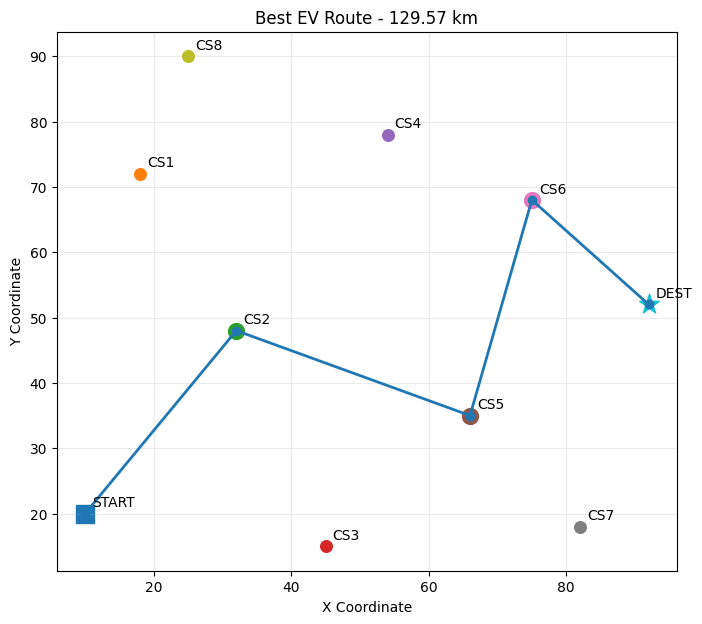

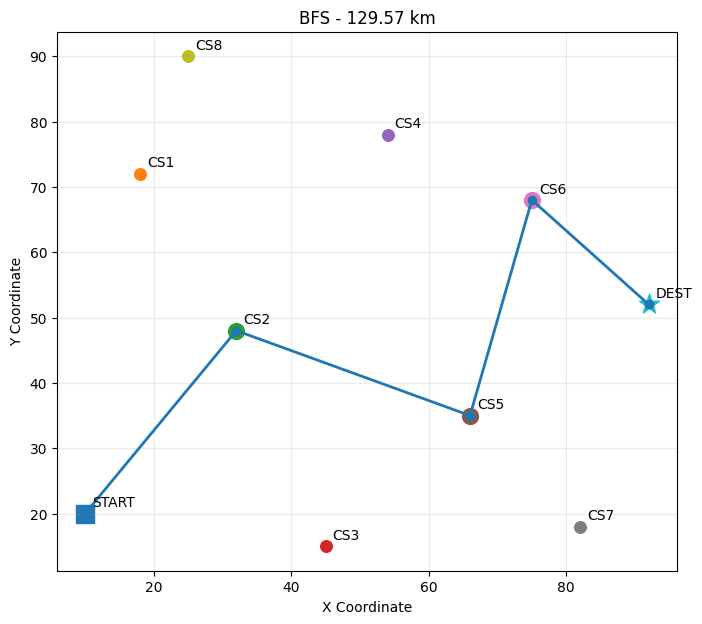

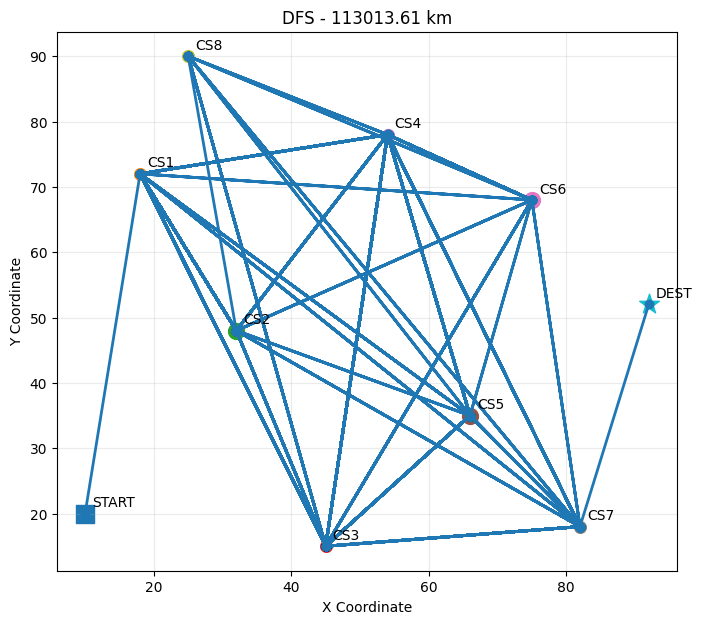

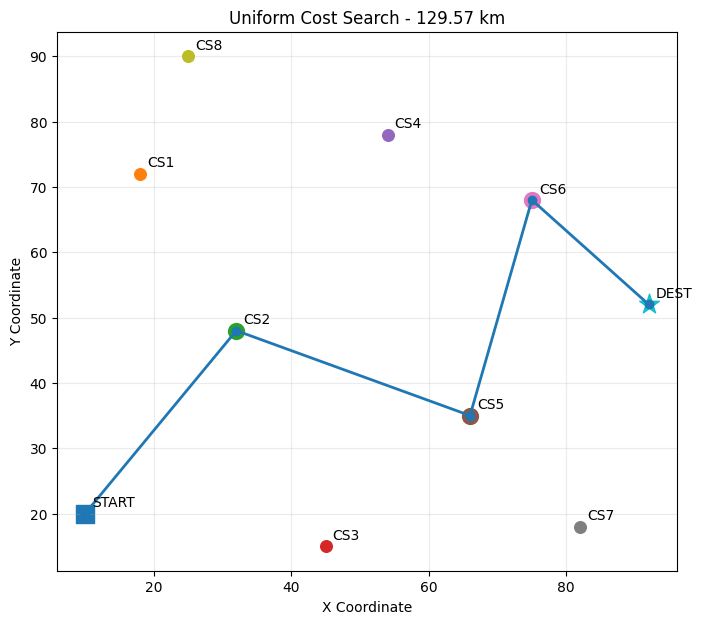

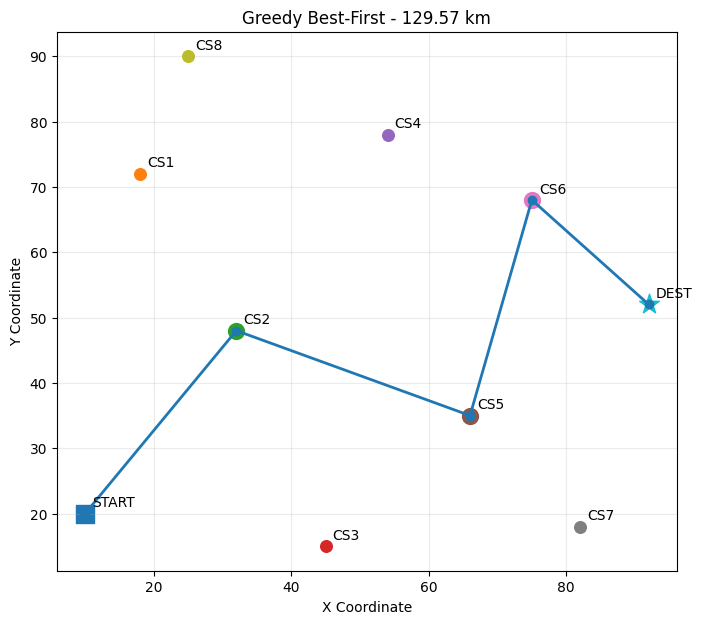

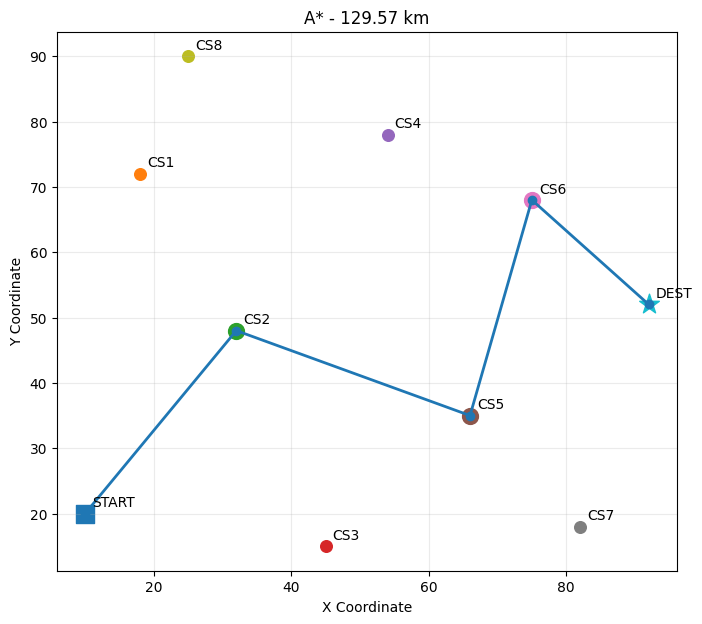

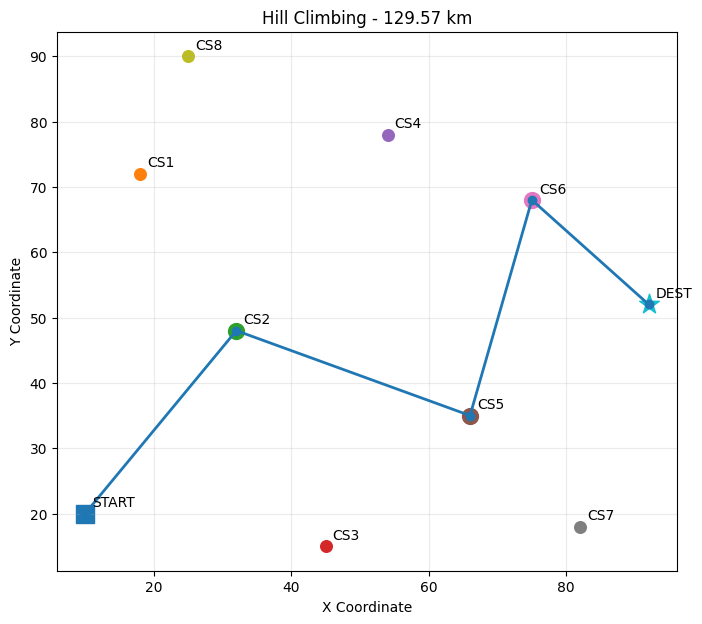

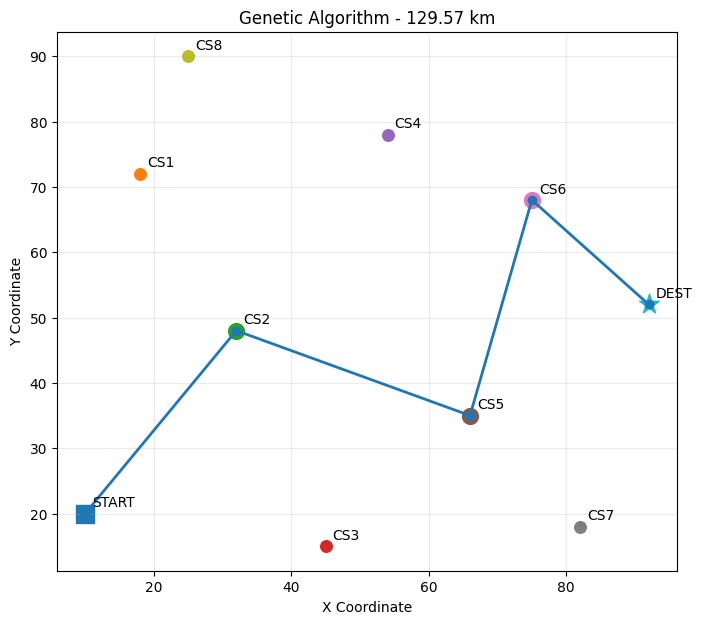

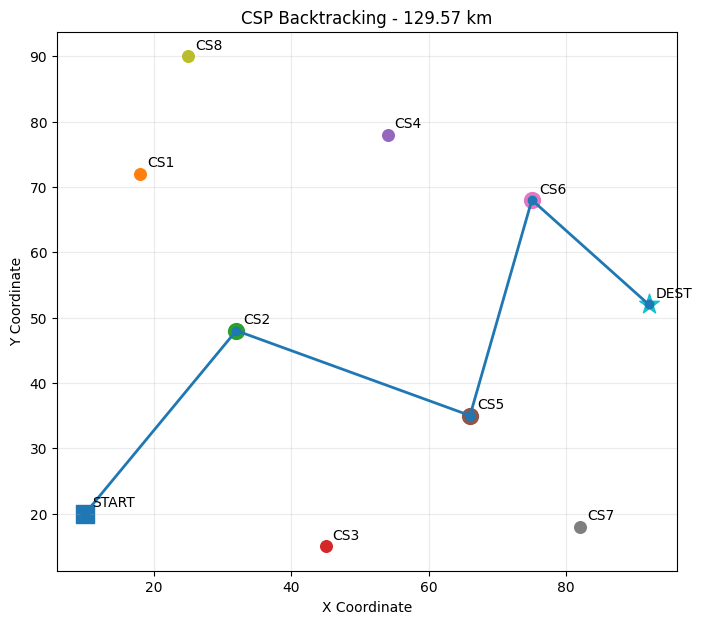

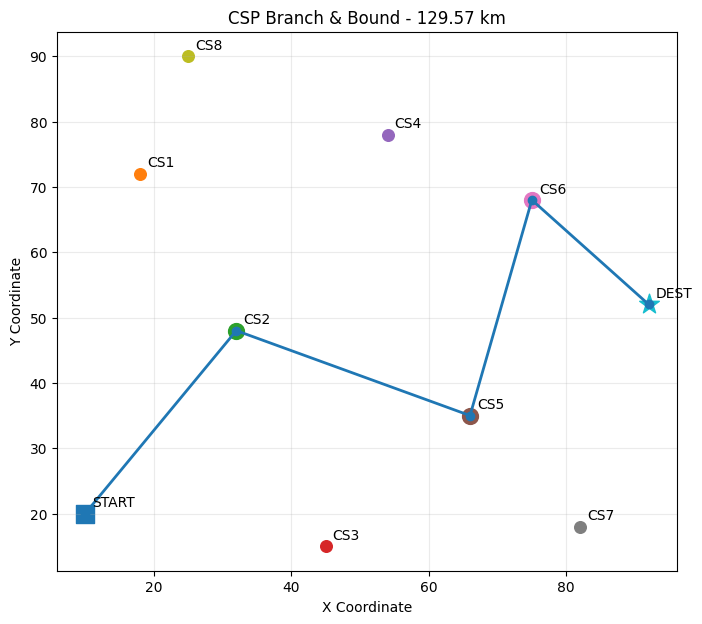

In [ ]:
def plot_route(
    route,
    title
):

    if route is None:

        print(
            "No feasible route found."
        )

        return

    xs = [
        COORDS[
            NODE_NAMES[i]
        ][0]
        for i in route
    ]

    ys = [
        COORDS[
            NODE_NAMES[i]
        ][1]
        for i in route
    ]

    plt.figure(
        figsize=(8, 7)
    )

    # Plot all locations

    for node in NODE_NAMES:

        x, y = COORDS[node]

        if node == "START":

            plt.scatter(
                x,
                y,
                s=180,
                marker="s"
            )

        elif node == "DEST":

            plt.scatter(
                x,
                y,
                s=220,
                marker="*"
            )

        elif node in REQUIRED_STATIONS:

            plt.scatter(
                x,
                y,
                s=130,
                marker="o"
            )

        else:

            plt.scatter(
                x,
                y,
                s=70
            )

        plt.annotate(
            node,
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    # Plot route

    plt.plot(
        xs,
        ys,
        marker="o",
        linewidth=2
    )

    plt.title(title)

    plt.xlabel(
        "X Coordinate"
    )

    plt.ylabel(
        "Y Coordinate"
    )

    plt.grid(
        alpha=0.25
    )

    plt.show()


# Best route
best_row = results_df.iloc[0]

best_route = [
    NODE_NAMES.index(x)
    for x in best_row["Route"].split(" -> ")
]

plot_route(
    best_route,
    f"Best EV Route - {best_row['Distance (km)']:.2f} km"
)


# Every algorithm
for _, row in results_df.iterrows():

    if pd.isna(row["Route"]):

        continue

    route = [
        NODE_NAMES.index(x)
        for x in row["Route"].split(" -> ")
    ]

    plot_route(
        route,
        f"{row['Algorithm']} - "
        f"{row['Distance (km)']:.2f} km"
    )

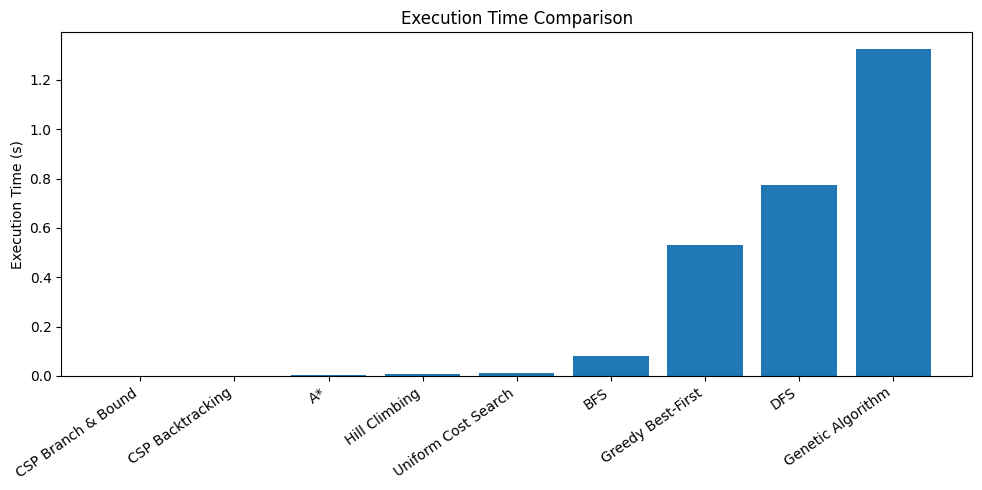

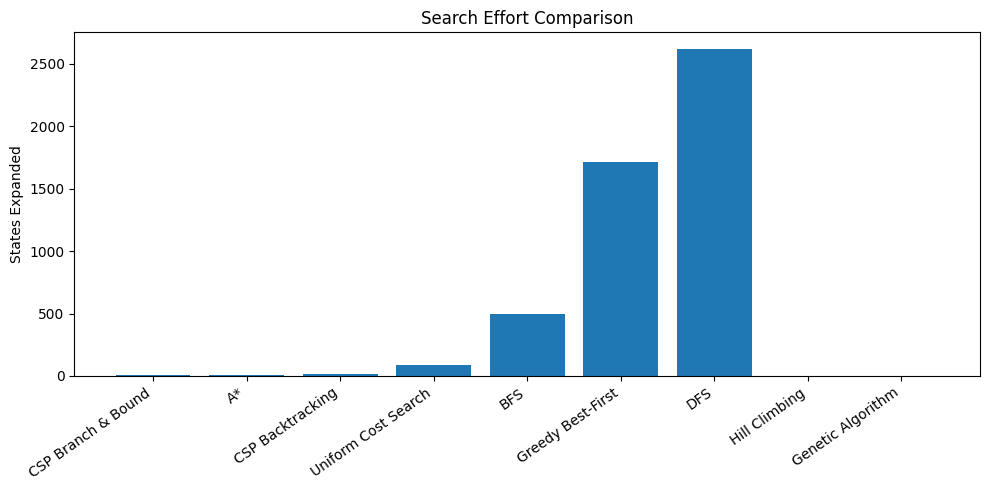

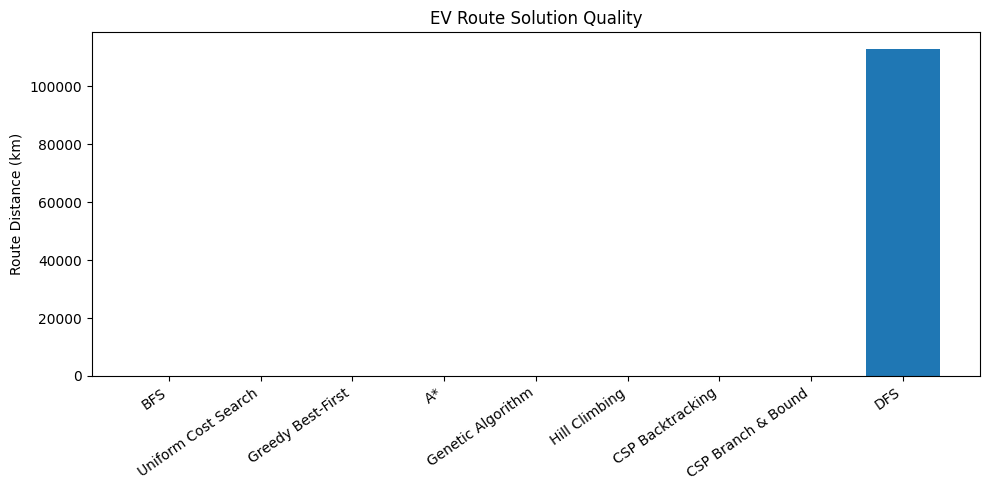

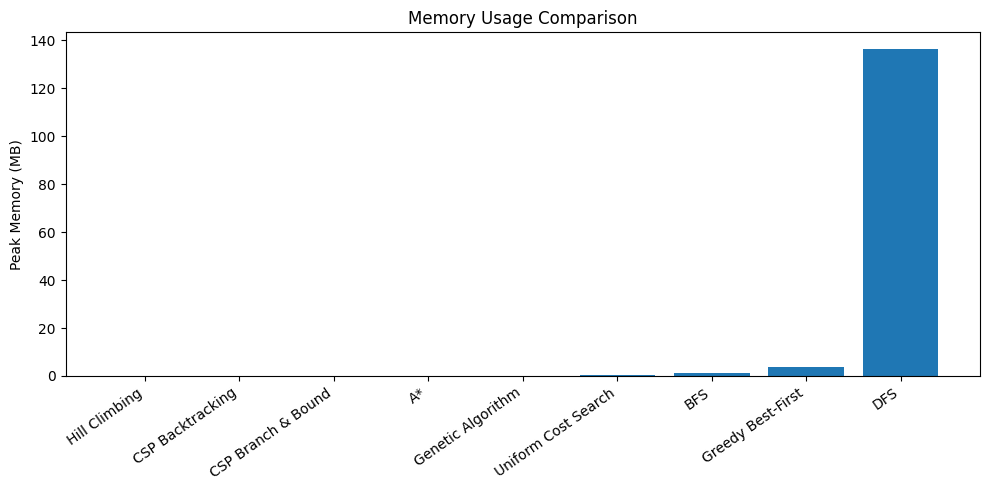

In [ ]:
# =========================================================
# EXECUTION TIME
# =========================================================

plot_df = (
    results_df
    .dropna(
        subset=["Time (s)"]
    )
    .sort_values("Time (s)")
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    plot_df["Algorithm"],
    plot_df["Time (s)"]
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.ylabel(
    "Execution Time (s)"
)

plt.title(
    "Execution Time Comparison"
)

plt.tight_layout()

plt.show()


# =========================================================
# SEARCH EFFORT
# =========================================================

plot_df = (
    results_df
    .sort_values(
        "States Expanded",
        na_position="last"
    )
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    plot_df["Algorithm"],
    plot_df[
        "States Expanded"
    ].fillna(0)
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.ylabel(
    "States Expanded"
)

plt.title(
    "Search Effort Comparison"
)

plt.tight_layout()

plt.show()


# =========================================================
# SOLUTION QUALITY
# =========================================================

plot_df = (
    results_df
    .sort_values(
        "Distance (km)"
    )
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    plot_df["Algorithm"],
    plot_df["Distance (km)"]
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.ylabel(
    "Route Distance (km)"
)

plt.title(
    "EV Route Solution Quality"
)

plt.tight_layout()

plt.show()


# =========================================================
# MEMORY
# =========================================================

plot_df = (
    results_df
    .sort_values(
        "Peak Memory (MB)"
    )
)

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    plot_df["Algorithm"],
    plot_df["Peak Memory (MB)"]
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.ylabel(
    "Peak Memory (MB)"
)

plt.title(
    "Memory Usage Comparison"
)

plt.tight_layout()

plt.show()

,Charging Stations,Algorithm,Distance (km),Time (s),States Expanded
0,5,BFS,NaN,NaN,NaN
1,5,DFS,NaN,NaN,NaN
2,5,UCS,NaN,NaN,NaN
3,5,Greedy,NaN,NaN,NaN
4,5,A*,NaN,NaN,NaN
5,5,Hill Climbing,NaN,NaN,NaN
6,5,Genetic Algorithm,NaN,NaN,NaN
7,5,CSP Branch & Bound,NaN,NaN,NaN
8,7,BFS,NaN,NaN,NaN
9,7,DFS,NaN,NaN,NaN


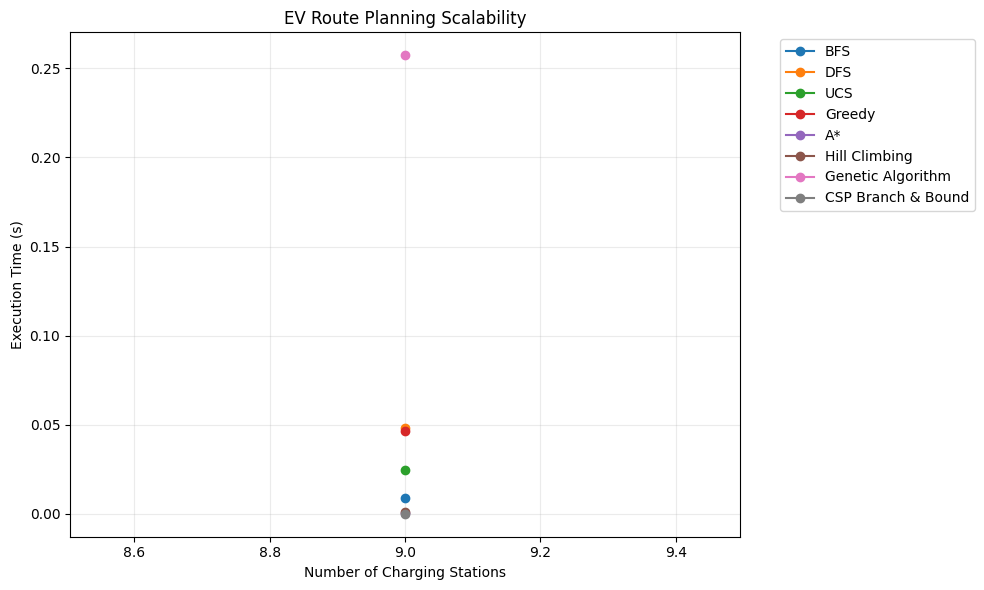

In [ ]:
scalability_sizes = [5, 7, 9]

scalability_rows = []


for n in scalability_sizes:

    selected_nodes = [
        "START"
    ] + [
        f"CS{i}"
        for i in range(
            1,
            min(n, 8) + 1
        )
    ] + [
        "DEST"
    ]

    selected_indices = [
        NODE_NAMES.index(x)
        for x in selected_nodes
    ]

    sub_dist = DIST[
        np.ix_(
            selected_indices,
            selected_indices
        )
    ]

    # Temporarily create a smaller
    # required-station set

    original_required = REQUIRED_STATIONS.copy()

    available_cs = [
        x for x in selected_nodes
        if x.startswith("CS")
    ]

    required_for_test = set(
        available_cs[
            :min(
                3,
                len(available_cs)
            )
        ]
    )

    REQUIRED_STATIONS.clear()

    REQUIRED_STATIONS.update(
        required_for_test
    )


    algorithms = [

        (
            "BFS",
            lambda:
            bfs_ev(sub_dist)
        ),

        (
            "DFS",
            lambda:
            dfs_ev(sub_dist)
        ),

        (
            "UCS",
            lambda:
            ucs_ev(sub_dist)
        ),

        (
            "Greedy",
            lambda:
            greedy_ev(sub_dist)
        ),

        (
            "A*",
            lambda:
            astar_ev(sub_dist)
        ),

        (
            "Hill Climbing",
            lambda:
            hill_climbing_ev(
                sub_dist,
                restarts=20,
                max_iter=500
            )
        ),

        (
            "Genetic Algorithm",
            lambda:
            genetic_algorithm_ev(
                sub_dist,
                population_size=60,
                generations=200
            )
        ),

        (
            "CSP Branch & Bound",
            lambda:
            branch_and_bound_ev(
                sub_dist
            )
        )

    ]


    for name, fn in algorithms:

        t0 = time.perf_counter()

        try:

            output = fn()

            elapsed = (
                time.perf_counter()
                - t0
            )

            if name == "Hill Climbing":

                route, cost, iterations, success = output

                expanded = np.nan

            elif name == "Genetic Algorithm":

                route, cost, generations, history = output

                expanded = np.nan

            else:

                route, cost, expanded = output


            scalability_rows.append([

                n,
                name,
                round(
                    cost,
                    2
                ),
                elapsed,
                expanded

            ])

        except Exception:

            scalability_rows.append([

                n,
                name,
                np.nan,
                np.nan,
                np.nan

            ])


    REQUIRED_STATIONS.clear()

    REQUIRED_STATIONS.update(
        original_required
    )


scalability_df = pd.DataFrame(

    scalability_rows,

    columns=[
        "Charging Stations",
        "Algorithm",
        "Distance (km)",
        "Time (s)",
        "States Expanded"
    ]
)


display(
    scalability_df
)


# =========================================================
# SCALABILITY GRAPH
# =========================================================

plt.figure(
    figsize=(10, 6)
)

for name in (
    scalability_df[
        "Algorithm"
    ].unique()
):

    temp = scalability_df[
        scalability_df[
            "Algorithm"
        ] == name
    ]

    plt.plot(
        temp[
            "Charging Stations"
        ],
        temp[
            "Time (s)"
        ],
        marker="o",
        label=name
    )


plt.xlabel(
    "Number of Charging Stations"
)

plt.ylabel(
    "Execution Time (s)"
)

plt.title(
    "EV Route Planning Scalability"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

,Charging Stations,Algorithm,Distance (km),Time (s),States Expanded
0,5,BFS,NaN,NaN,NaN
1,5,DFS,NaN,NaN,NaN
2,5,UCS,NaN,NaN,NaN
3,5,Greedy,NaN,NaN,NaN
4,5,A*,NaN,NaN,NaN
5,5,Hill Climbing,NaN,NaN,NaN
6,5,Genetic Algorithm,NaN,NaN,NaN
7,5,CSP Branch & Bound,NaN,NaN,NaN
8,7,BFS,NaN,NaN,NaN
9,7,DFS,NaN,NaN,NaN


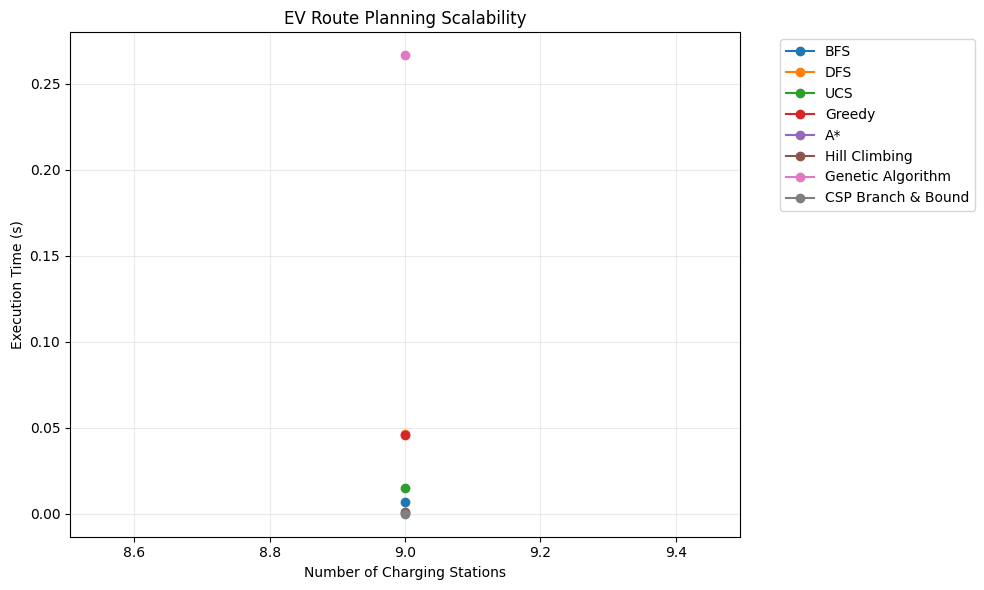

In [ ]:
scalability_sizes = [5, 7, 9]

scalability_rows = []


for n in scalability_sizes:

    selected_nodes = [
        "START"
    ] + [
        f"CS{i}"
        for i in range(
            1,
            min(n, 8) + 1
        )
    ] + [
        "DEST"
    ]

    selected_indices = [
        NODE_NAMES.index(x)
        for x in selected_nodes
    ]

    sub_dist = DIST[
        np.ix_(
            selected_indices,
            selected_indices
        )
    ]

    # Temporarily create a smaller
    # required-station set

    original_required = REQUIRED_STATIONS.copy()

    available_cs = [
        x for x in selected_nodes
        if x.startswith("CS")
    ]

    required_for_test = set(
        available_cs[
            :min(
                3,
                len(available_cs)
            )
        ]
    )

    REQUIRED_STATIONS.clear()

    REQUIRED_STATIONS.update(
        required_for_test
    )


    algorithms = [

        (
            "BFS",
            lambda:
            bfs_ev(sub_dist)
        ),

        (
            "DFS",
            lambda:
            dfs_ev(sub_dist)
        ),

        (
            "UCS",
            lambda:
            ucs_ev(sub_dist)
        ),

        (
            "Greedy",
            lambda:
            greedy_ev(sub_dist)
        ),

        (
            "A*",
            lambda:
            astar_ev(sub_dist)
        ),

        (
            "Hill Climbing",
            lambda:
            hill_climbing_ev(
                sub_dist,
                restarts=20,
                max_iter=500
            )
        ),

        (
            "Genetic Algorithm",
            lambda:
            genetic_algorithm_ev(
                sub_dist,
                population_size=60,
                generations=200
            )
        ),

        (
            "CSP Branch & Bound",
            lambda:
            branch_and_bound_ev(
                sub_dist
            )
        )

    ]


    for name, fn in algorithms:

        t0 = time.perf_counter()

        try:

            output = fn()

            elapsed = (
                time.perf_counter()
                - t0
            )

            if name == "Hill Climbing":

                route, cost, iterations, success = output

                expanded = np.nan

            elif name == "Genetic Algorithm":

                route, cost, generations, history = output

                expanded = np.nan

            else:

                route, cost, expanded = output


            scalability_rows.append([

                n,
                name,
                round(
                    cost,
                    2
                ),
                elapsed,
                expanded

            ])

        except Exception:

            scalability_rows.append([

                n,
                name,
                np.nan,
                np.nan,
                np.nan

            ])


    REQUIRED_STATIONS.clear()

    REQUIRED_STATIONS.update(
        original_required
    )


scalability_df = pd.DataFrame(

    scalability_rows,

    columns=[
        "Charging Stations",
        "Algorithm",
        "Distance (km)",
        "Time (s)",
        "States Expanded"
    ]
)


display(
    scalability_df
)


# =========================================================
# SCALABILITY GRAPH
# =========================================================

plt.figure(
    figsize=(10, 6)
)

for name in (
    scalability_df[
        "Algorithm"
    ].unique()
):

    temp = scalability_df[
        scalability_df[
            "Algorithm"
        ] == name
    ]

    plt.plot(
        temp[
            "Charging Stations"
        ],
        temp[
            "Time (s)"
        ],
        marker="o",
        label=name
    )


plt.xlabel(
    "Number of Charging Stations"
)

plt.ylabel(
    "Execution Time (s)"
)

plt.title(
    "EV Route Planning Scalability"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()

In [ ]:
print("""
1. BFS, UCS, Greedy, A*, Hill Climbing, GA and CSP found a feasible route of 129.57 km.
2. DFS produced a much longer route of 113013.61 km.
3. BFS expanded 500 states, DFS 2622, UCS 86 and A* only 12.
4. A* combines path cost and heuristic for efficient search.
5. Hill Climbing uses restarts, while GA searches multiple candidate routes.
6. CSP methods use constraints, with Branch & Bound using cost-based pruning.
7. CSP Branch & Bound was fastest, while Hill Climbing used the lowest memory.
8. EV routing considers battery, charging-station and destination constraints.
9. Different search methods vary in route quality, time, memory and search effort.
""")


1. BFS, UCS, Greedy, A*, Hill Climbing, GA and CSP found a feasible route of 129.57 km.
2. DFS produced a much longer route of 113013.61 km.
3. BFS expanded 500 states, DFS 2622, UCS 86 and A* only 12.
4. A* combines path cost and heuristic for efficient search.
5. Hill Climbing uses restarts, while GA searches multiple candidate routes.
6. CSP methods use constraints, with Branch & Bound using cost-based pruning.
7. CSP Branch & Bound was fastest, while Hill Climbing used the lowest memory.
8. EV routing considers battery, charging-station and destination constraints.
9. Different search methods vary in route quality, time, memory and search effort.

